# High-resolution BraTS U-Net visualisation in Napari

This notebook is a **minimal experiment** for testing the existing pretrained 128×128 U-Net at the native BraTS spatial resolution of **240×240**, without fine-tuning.

It deliberately changes only the spatial input resolution while preserving the original preprocessing logic as closely as possible. It then opens a Napari viewer inspired by the original project viewer, with:

- native-resolution FLAIR MRI;
- original 128×128 prediction, upsampled only for display;
- zero-shot 240×240 prediction using the same pretrained weights;
- expert ground-truth segmentation;
- optional conformal uncertainty **only after a new 240-resolution threshold is supplied**;
- layer toggles, opacity controls, slice controls, case loading, rotation, and screenshots.

### Provenance

The U-Net architecture below reproduces the architecture used in the original project, which was adapted from the public BraTS U-Net implementation by Rastislav Kopál. This notebook is intended to evaluate the already-existing pretrained weights at a new input resolution; it does not claim the U-Net architecture as a new contribution.

### Important statistical note

The old conformal threshold should **not** be reused for quantitative claims at 240×240. Changing the model input resolution changes its softmax-score distribution. A new conformal threshold should be calibrated on the 240×240 predictions before interpreting the uncertainty layer as conformally valid.


## 1. Environment

This notebook assumes that the BraTS2020 training data and `model_per_class.h5` are available locally.

If Napari is not installed, install it in the same environment as the notebook, for example:

```bash
pip install "napari[pyqt6]" nibabel opencv-python imageio
```

TensorFlow should already be installed in the environment that can load your existing `.h5` model.


In [1]:
from pathlib import Path
import os

import cv2
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
import keras.backend as K

print("TensorFlow:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())


Matplotlib is building the font cache; this may take a moment.


TensorFlow: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Paths and experiment configuration

For the cleanest comparison we keep the original slice range used by the model experiment: 100 slices beginning at z=22. That means the only intended intervention is

\[
128\times128 \longrightarrow 240\times240.
\]

After this works, you can separately test the full 155-slice volume.


In [2]:
# ---- EDIT THESE PATHS IF NEEDED ------------------------------------------------

PROJECT_ROOT = Path.cwd()

# If the notebook lives in a notebooks/ subdirectory, this tries the parent too.
if not (PROJECT_ROOT / "BraTS2020_TrainingData").exists():
    if (PROJECT_ROOT.parent / "BraTS2020_TrainingData").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent

DATA_ROOT = (
    PROJECT_ROOT
    / "BraTS2020_TrainingData"
    / "MICCAI_BraTS2020_TrainingData"
)

MODEL_PATH = PROJECT_ROOT / "model_per_class.h5"

# ---- Experiment configuration --------------------------------------------------

ORIGINAL_IMG_SIZE = 128
NATIVE_IMG_SIZE = 240

VOLUME_SLICES = 100
VOLUME_START_AT = 22

DEFAULT_CASE = "070"

SEGMENT_CLASSES = {
    0: "Background / no tumour",
    1: "Necrotic / non-enhancing core",
    2: "Edema",
    3: "Enhancing tumour",
}

# IMPORTANT:
# Leave this as None until you recalibrate the conformal method using the
# 240x240 model outputs. The viewer will still work without it.
LAMBDA_HAT_240 = None

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_ROOT:", DATA_ROOT)
print("MODEL_PATH:", MODEL_PATH)

assert DATA_ROOT.exists(), f"BraTS data folder not found: {DATA_ROOT}"
assert MODEL_PATH.exists(), f"Pretrained model not found: {MODEL_PATH}"


PROJECT_ROOT: /Users/sanjayvonk/Development/BrainTumorSegmentation-1/Research Project
DATA_ROOT: /Users/sanjayvonk/Development/BrainTumorSegmentation-1/Research Project/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData
MODEL_PATH: /Users/sanjayvonk/Development/BrainTumorSegmentation-1/Research Project/model_per_class.h5


## 3. Recreate the original U-Net architecture

The network is fully convolutional, so its convolutional weights do not depend on the spatial image size. We therefore instantiate the same architecture at 240×240 and copy the learned weights from the 128×128 model.


In [3]:
# Custom metrics used by the original saved model.

def dice_coef(y_true, y_pred, smooth=1.0):
    class_num = 4
    total = 0.0
    for i in range(class_num):
        y_true_f = K.flatten(y_true[:, :, :, i])
        y_pred_f = K.flatten(y_pred[:, :, :, i])
        intersection = K.sum(y_true_f * y_pred_f)
        score = (
            (2.0 * intersection + smooth)
            / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)
        )
        total += score
    return total / class_num


def dice_coef_necrotic(y_true, y_pred, epsilon=1e-6):
    intersection = K.sum(K.abs(y_true[:, :, :, 1] * y_pred[:, :, :, 1]))
    return (2.0 * intersection) / (
        K.sum(K.square(y_true[:, :, :, 1]))
        + K.sum(K.square(y_pred[:, :, :, 1]))
        + epsilon
    )


def dice_coef_edema(y_true, y_pred, epsilon=1e-6):
    intersection = K.sum(K.abs(y_true[:, :, :, 2] * y_pred[:, :, :, 2]))
    return (2.0 * intersection) / (
        K.sum(K.square(y_true[:, :, :, 2]))
        + K.sum(K.square(y_pred[:, :, :, 2]))
        + epsilon
    )


def dice_coef_enhancing(y_true, y_pred, epsilon=1e-6):
    intersection = K.sum(K.abs(y_true[:, :, :, 3] * y_pred[:, :, :, 3]))
    return (2.0 * intersection) / (
        K.sum(K.square(y_true[:, :, :, 3]))
        + K.sum(K.square(y_pred[:, :, :, 3]))
        + epsilon
    )


def precision(y_true, y_pred):
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
    return true_positives / (predicted_positives + K.epsilon())


def sensitivity(y_true, y_pred):
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    return true_positives / (possible_positives + K.epsilon())


def specificity(y_true, y_pred):
    true_negatives = K.sum(
        K.round(K.clip((1 - y_true) * (1 - y_pred), 0, 1))
    )
    possible_negatives = K.sum(K.round(K.clip(1 - y_true, 0, 1)))
    return true_negatives / (possible_negatives + K.epsilon())


def build_unet(inputs, ker_init="he_normal", dropout=0.2):
    conv1 = keras.layers.Conv2D(
        32, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(inputs)
    conv1 = keras.layers.Conv2D(
        32, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(conv1)

    pool = keras.layers.MaxPooling2D(pool_size=(2, 2))(conv1)

    conv = keras.layers.Conv2D(
        64, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(pool)
    conv = keras.layers.Conv2D(
        64, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(conv)

    pool1 = keras.layers.MaxPooling2D(pool_size=(2, 2))(conv)

    conv2 = keras.layers.Conv2D(
        128, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(pool1)
    conv2 = keras.layers.Conv2D(
        128, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(conv2)

    pool2 = keras.layers.MaxPooling2D(pool_size=(2, 2))(conv2)

    conv3 = keras.layers.Conv2D(
        256, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(pool2)
    conv3 = keras.layers.Conv2D(
        256, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(conv3)

    pool4 = keras.layers.MaxPooling2D(pool_size=(2, 2))(conv3)

    conv5 = keras.layers.Conv2D(
        512, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(pool4)
    conv5 = keras.layers.Conv2D(
        512, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(conv5)

    drop5 = keras.layers.Dropout(dropout)(conv5)

    up7 = keras.layers.Conv2D(
        256, 2, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(keras.layers.UpSampling2D(size=(2, 2))(drop5))
    merge7 = keras.layers.concatenate([conv3, up7], axis=3)
    conv7 = keras.layers.Conv2D(
        256, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(merge7)
    conv7 = keras.layers.Conv2D(
        256, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(conv7)

    up8 = keras.layers.Conv2D(
        128, 2, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(keras.layers.UpSampling2D(size=(2, 2))(conv7))
    merge8 = keras.layers.concatenate([conv2, up8], axis=3)
    conv8 = keras.layers.Conv2D(
        128, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(merge8)
    conv8 = keras.layers.Conv2D(
        128, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(conv8)

    up9 = keras.layers.Conv2D(
        64, 2, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(keras.layers.UpSampling2D(size=(2, 2))(conv8))
    merge9 = keras.layers.concatenate([conv, up9], axis=3)
    conv9 = keras.layers.Conv2D(
        64, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(merge9)
    conv9 = keras.layers.Conv2D(
        64, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(conv9)

    up = keras.layers.Conv2D(
        32, 2, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(keras.layers.UpSampling2D(size=(2, 2))(conv9))
    merge = keras.layers.concatenate([conv1, up], axis=3)
    conv = keras.layers.Conv2D(
        32, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(merge)
    conv = keras.layers.Conv2D(
        32, 3, activation="relu", padding="same",
        kernel_initializer=ker_init
    )(conv)

    outputs = keras.layers.Conv2D(4, (1, 1), activation="softmax")(conv)
    return keras.Model(inputs=inputs, outputs=outputs)


In [4]:
# Load the existing 128x128 model.
custom_objects = {
    "dice_coef": dice_coef,
    "precision": precision,
    "sensitivity": sensitivity,
    "specificity": specificity,
    "dice_coef_necrotic": dice_coef_necrotic,
    "dice_coef_edema": dice_coef_edema,
    "dice_coef_enhancing": dice_coef_enhancing,
}

model_128 = keras.models.load_model(
    MODEL_PATH,
    custom_objects=custom_objects,
    compile=False,
)

# Rebuild the same architecture at 240x240 and copy all learned weights.
input_240 = keras.Input((NATIVE_IMG_SIZE, NATIVE_IMG_SIZE, 2))
model_240 = build_unet(input_240, ker_init="he_normal", dropout=0.2)
model_240.set_weights(model_128.get_weights())

print("Original model input:", model_128.input_shape)
print("High-resolution model input:", model_240.input_shape)
print("Number of transferred weight arrays:", len(model_240.get_weights()))


Original model input: (None, 128, 128, 2)
High-resolution model input: (None, 240, 240, 2)
Number of transferred weight arrays: 46


## 4. Native-resolution case loading and prediction

The 128×128 path reproduces the old behaviour by resizing each FLAIR and T1ce slice.

The 240×240 path feeds the original BraTS slices directly into the same learned filters. No fine-tuning is performed.


In [5]:
def normalise_like_original(x):
    """Preserve the original notebook's volume-wise max normalisation."""
    max_value = np.max(x)
    if max_value <= 0:
        return x.astype(np.float32)
    return (x / max_value).astype(np.float32)


def get_case_path(case_id):
    case_id = str(case_id).zfill(3)
    return DATA_ROOT / f"BraTS20_Training_{case_id}"


def load_case_volumes(case_id):
    case_id = str(case_id).zfill(3)
    case_path = get_case_path(case_id)

    flair = nib.load(
        case_path / f"BraTS20_Training_{case_id}_flair.nii"
    ).get_fdata().astype(np.float32)

    t1ce = nib.load(
        case_path / f"BraTS20_Training_{case_id}_t1ce.nii"
    ).get_fdata().astype(np.float32)

    gt = nib.load(
        case_path / f"BraTS20_Training_{case_id}_seg.nii"
    ).get_fdata()

    # BraTS label 4 -> project class 3, as in the old notebook.
    gt[gt == 4] = 3
    gt = gt.astype(np.uint8)

    z0 = VOLUME_START_AT
    z1 = VOLUME_START_AT + VOLUME_SLICES

    return {
        "case_id": case_id,
        "flair": flair[:, :, z0:z1],
        "t1ce": t1ce[:, :, z0:z1],
        "gt": gt[:, :, z0:z1],
    }


def make_input_128(volumes):
    X = np.empty(
        (VOLUME_SLICES, ORIGINAL_IMG_SIZE, ORIGINAL_IMG_SIZE, 2),
        dtype=np.float32,
    )

    for j in range(VOLUME_SLICES):
        X[j, :, :, 0] = cv2.resize(
            volumes["flair"][:, :, j],
            (ORIGINAL_IMG_SIZE, ORIGINAL_IMG_SIZE),
            interpolation=cv2.INTER_AREA,
        )
        X[j, :, :, 1] = cv2.resize(
            volumes["t1ce"][:, :, j],
            (ORIGINAL_IMG_SIZE, ORIGINAL_IMG_SIZE),
            interpolation=cv2.INTER_AREA,
        )

    return normalise_like_original(X)


def make_input_240(volumes):
    # Native BraTS axial slices are already 240x240.
    flair = np.moveaxis(volumes["flair"], 2, 0)
    t1ce = np.moveaxis(volumes["t1ce"], 2, 0)

    X = np.stack([flair, t1ce], axis=-1).astype(np.float32)

    assert X.shape == (
        VOLUME_SLICES,
        NATIVE_IMG_SIZE,
        NATIVE_IMG_SIZE,
        2,
    ), f"Unexpected native shape: {X.shape}"

    return normalise_like_original(X)


def predict_case(case_id, batch_size_128=16, batch_size_240=4):
    volumes = load_case_volumes(case_id)

    X128 = make_input_128(volumes)
    X240 = make_input_240(volumes)

    print(f"Predicting case {volumes['case_id']} at 128x128...")
    probs_128 = model_128.predict(
        X128, batch_size=batch_size_128, verbose=1
    )

    print(f"Predicting case {volumes['case_id']} at 240x240...")
    probs_240 = model_240.predict(
        X240, batch_size=batch_size_240, verbose=1
    )

    labels_128 = np.argmax(probs_128, axis=-1).astype(np.uint8)
    labels_240 = np.argmax(probs_240, axis=-1).astype(np.uint8)

    # Upsample the 128 prediction only for native-resolution comparison/display.
    labels_128_up = np.empty(
        (VOLUME_SLICES, NATIVE_IMG_SIZE, NATIVE_IMG_SIZE),
        dtype=np.uint8,
    )
    for j in range(VOLUME_SLICES):
        labels_128_up[j] = cv2.resize(
            labels_128[j],
            (NATIVE_IMG_SIZE, NATIVE_IMG_SIZE),
            interpolation=cv2.INTER_NEAREST,
        )

    # Napari uses (z, y, x); preserve the orientation used in the old viewer.
    flair_zyx = np.transpose(volumes["flair"], (2, 0, 1))
    gt_zyx = np.transpose(volumes["gt"], (2, 0, 1))

    return {
        **volumes,
        "flair_zyx": flair_zyx,
        "gt_zyx": gt_zyx,
        "probs_128": probs_128,
        "probs_240": probs_240,
        "labels_128_up": labels_128_up,
        "labels_240": labels_240,
    }


## 5. Quick sanity-check metrics

These are not the final paper metrics. They are simply useful for checking whether zero-shot 240×240 inference has catastrophically broken the segmentation before opening Napari.


In [6]:
def whole_tumour_dice(pred_labels, gt_labels, eps=1e-8):
    pred = pred_labels > 0
    true = gt_labels > 0
    intersection = np.logical_and(pred, true).sum()
    return (2.0 * intersection + eps) / (pred.sum() + true.sum() + eps)


def tumour_fnr(pred_labels, gt_labels):
    true_tumour = gt_labels > 0
    n_tumour = true_tumour.sum()
    if n_tumour == 0:
        return np.nan
    missed = np.logical_and(true_tumour, pred_labels == 0).sum()
    return missed / n_tumour


def compare_segmentations(result):
    gt = result["gt_zyx"]

    metrics = {
        "128 upsampled — whole-tumour Dice":
            whole_tumour_dice(result["labels_128_up"], gt),
        "240 zero-shot — whole-tumour Dice":
            whole_tumour_dice(result["labels_240"], gt),
        "128 upsampled — tumour FNR":
            tumour_fnr(result["labels_128_up"], gt),
        "240 zero-shot — tumour FNR":
            tumour_fnr(result["labels_240"], gt),
    }

    for name, value in metrics.items():
        print(f"{name}: {value:.4f}")

    return metrics


Predicting case 070 at 128x128...
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 325ms/step
Predicting case 070 at 240x240...
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 241ms/step
128 upsampled — whole-tumour Dice: 0.8418
240 zero-shot — whole-tumour Dice: 0.8329
128 upsampled — tumour FNR: 0.1772
240 zero-shot — tumour FNR: 0.1053


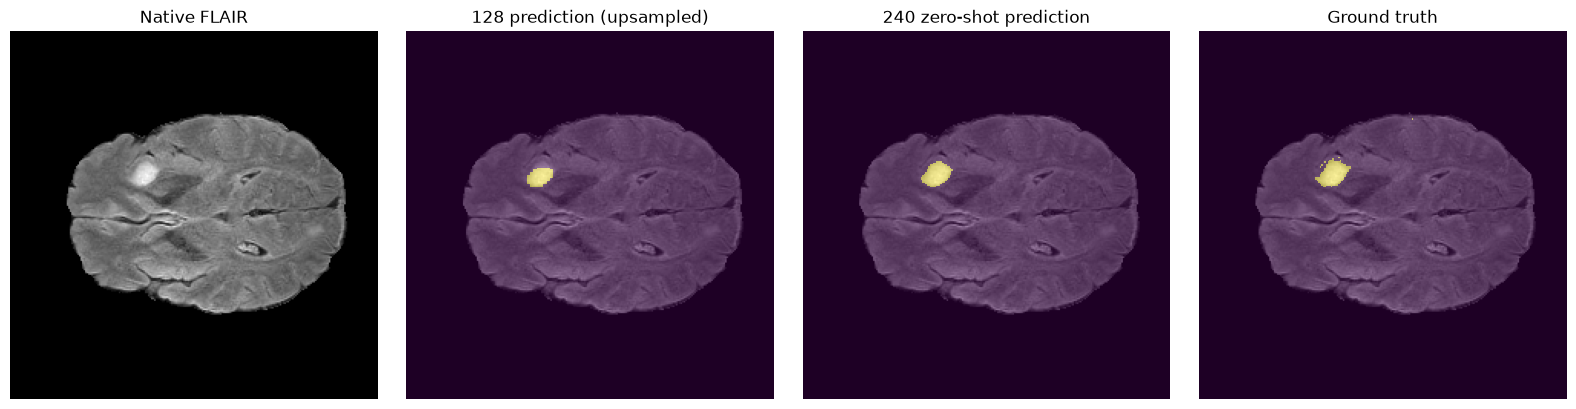

In [7]:
# Run one case before launching Napari.
result = predict_case(DEFAULT_CASE)
metrics = compare_segmentations(result)

# Optional quick 2D check.
slice_id = VOLUME_SLICES // 2

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(result["flair_zyx"][slice_id], cmap="gray")
axes[0].set_title("Native FLAIR")

axes[1].imshow(result["flair_zyx"][slice_id], cmap="gray")
axes[1].imshow(
    result["labels_128_up"][slice_id],
    alpha=0.45,
    interpolation="nearest",
)
axes[1].set_title("128 prediction (upsampled)")

axes[2].imshow(result["flair_zyx"][slice_id], cmap="gray")
axes[2].imshow(
    result["labels_240"][slice_id],
    alpha=0.45,
    interpolation="nearest",
)
axes[2].set_title("240 zero-shot prediction")

axes[3].imshow(result["flair_zyx"][slice_id], cmap="gray")
axes[3].imshow(
    result["gt_zyx"][slice_id],
    alpha=0.45,
    interpolation="nearest",
)
axes[3].set_title("Ground truth")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 6. Optional conformal prediction-set helper

The function is included because the old Napari viewer displayed the conformal set size as an uncertainty volume.

The viewer will only display the conformal layer when `LAMBDA_HAT_240` is not `None`. Calibrate a fresh threshold from 240×240 predictions before using it for scientific interpretation.


In [8]:
def conformal_prediction_set(smx_scores, lambda_hat):
    """APS-style prediction sets used in the original project."""
    smx_scores = np.asarray(smx_scores)
    val_pi = smx_scores.argsort(1)[:, ::-1]
    val_srt = np.take_along_axis(
        smx_scores, val_pi, axis=1
    ).cumsum(axis=1)

    exceeds_lambda = val_srt >= lambda_hat
    boundaries = np.argmax(exceeds_lambda, axis=1)

    prediction_sets = np.zeros_like(val_srt, dtype=bool)
    col_indices = np.arange(val_srt.shape[1])
    within_boundary = col_indices <= boundaries[:, None]

    prediction_sets[
        np.arange(val_srt.shape[0])[:, None],
        val_pi
    ] = within_boundary

    return prediction_sets


def make_uncertainty_volume_240(probs_240, lambda_hat):
    """Return prediction-set size in (z, y, x) order."""
    flat = probs_240.reshape(-1, probs_240.shape[-1])
    sets = conformal_prediction_set(flat, lambda_hat)
    set_size = sets.sum(axis=1)

    return set_size.reshape(
        VOLUME_SLICES,
        NATIVE_IMG_SIZE,
        NATIVE_IMG_SIZE,
    )


## 7. Napari viewer

This keeps the structure of the old viewer but adds a direct comparison between the original 128×128 prediction and the zero-shot 240×240 prediction.

The viewer starts in 3D. Use the **Layers** tab to toggle overlays, **Slice** to switch to 2D slice mode, **Case** to load another BraTS case, and **Rotation** to control the 3D view.

The conformal layer is hidden until `LAMBDA_HAT_240` is supplied.


In [9]:
import napari
import matplotlib
import matplotlib.colors as mcolors

from qtpy.QtCore import QTimer, Qt
from qtpy.QtWidgets import (
    QApplication,
    QWidget,
    QVBoxLayout,
    QHBoxLayout,
    QCheckBox,
    QSlider,
    QLabel,
    QPushButton,
    QTabWidget,
    QFileDialog,
    QGroupBox,
    QLineEdit,
)


def _label_colormap():
    # Restrained, high-contrast colours for tumour subregions.
    return {
        0: (0.0, 0.0, 0.0, 0.0),
        1: (0.15, 0.75, 0.95, 1.0),
        2: (0.98, 0.75, 0.15, 1.0),
        3: (0.95, 0.25, 0.45, 1.0),
    }


def _camera(viewer):
    # Napari >= 0.9 exposes viewer.scene.camera; older versions use viewer.camera.
    if hasattr(viewer, "scene") and hasattr(viewer.scene, "camera"):
        return viewer.scene.camera
    return viewer.camera


def launch_napari_viewer(initial_result, lambda_hat_240=None):
    state = {
        "result": initial_result,
        "auto_rotate": False,
        "rotation_speed": 1,
        "auto_slice": False,
        "slice_speed": 1,
        "slice_direction": 1,
    }

    label_colormap = _label_colormap()
    scale = (1.0, 1.0, 1.0)  # native BraTS spatial resolution

    viewer = napari.Viewer(ndisplay=3, title="BraTS high-resolution comparison")

    mri_layer = viewer.add_image(
        initial_result["flair_zyx"],
        name="Brain MRI",
        colormap="gray",
        opacity=1.0,
        scale=scale,
        contrast_limits=(
            float(initial_result["flair_zyx"].min()),
            float(initial_result["flair_zyx"].max()),
        ),
        rendering="mip",
    )

    pred128_layer = viewer.add_labels(
        initial_result["labels_128_up"],
        name="Prediction — 128 upsampled",
        colormap=label_colormap,
        scale=scale,
        opacity=0.30,
        blending="translucent",
        visible=False,
    )

    pred240_layer = viewer.add_labels(
        initial_result["labels_240"],
        name="Prediction — 240 zero-shot",
        colormap=label_colormap,
        scale=scale,
        opacity=0.55,
        blending="translucent",
        visible=True,
    )

    gt_layer = viewer.add_labels(
        initial_result["gt_zyx"],
        name="Ground Truth",
        colormap=label_colormap,
        scale=scale,
        opacity=0.35,
        blending="translucent",
        visible=True,
    )

    if lambda_hat_240 is not None:
        uncertainty_data = make_uncertainty_volume_240(
            initial_result["probs_240"],
            lambda_hat_240,
        ).astype(np.float32)
        uncertainty_visible = True
    else:
        uncertainty_data = np.zeros_like(
            initial_result["flair_zyx"],
            dtype=np.float32,
        )
        uncertainty_visible = False

    uncertainty_layer = viewer.add_image(
        uncertainty_data,
        name="Conformal Uncertainty — 240",
        colormap="red",
        opacity=0.30,
        scale=scale,
        contrast_limits=(1.5, 4.0),
        blending="additive",
        visible=uncertainty_visible,
    )

    cam = _camera(viewer)
    try:
        cam.zoom = 2.5
    except Exception:
        pass

    # --------------------------------------------------------------------------
    # Timers
    # --------------------------------------------------------------------------

    rotation_timer = QTimer()
    rotation_timer.setInterval(50)

    def rotate_view():
        if not state["auto_rotate"]:
            return
        camera = _camera(viewer)
        angles = list(camera.angles)
        if len(angles) >= 2:
            angles[1] = (angles[1] + state["rotation_speed"]) % 360
            camera.angles = tuple(angles)

    rotation_timer.timeout.connect(rotate_view)
    rotation_timer.start()

    slice_timer = QTimer()
    slice_timer.setInterval(200)

    def move_slice():
        if not state["auto_slice"]:
            return

        current = int(viewer.dims.current_step[0])
        new = current + state["slice_direction"] * state["slice_speed"]

        if new >= VOLUME_SLICES:
            new = VOLUME_SLICES - 2
            state["slice_direction"] = -1
        elif new < 0:
            new = 1
            state["slice_direction"] = 1

        viewer.dims.set_current_step(0, new)

        if "panel" in state:
            panel = state["panel"]
            panel.slice_slider.blockSignals(True)
            panel.slice_slider.setValue(new)
            panel.slice_label.setText(f"Z-slice: {new}")
            panel.slice_slider.blockSignals(False)

    slice_timer.timeout.connect(move_slice)
    slice_timer.start()

    # --------------------------------------------------------------------------
    # Control panel
    # --------------------------------------------------------------------------

    class CombinedControlPanel(QWidget):
        def __init__(self):
            super().__init__()

            main_layout = QVBoxLayout()
            self.tabs = QTabWidget()

            # ---------------- Rotation ----------------
            rotation_tab = QWidget()
            rotation_layout = QVBoxLayout()

            self.auto_rotate_checkbox = QCheckBox("Enable auto-rotation")
            self.auto_rotate_checkbox.setChecked(False)
            self.auto_rotate_checkbox.stateChanged.connect(
                self.toggle_auto_rotate
            )
            rotation_layout.addWidget(self.auto_rotate_checkbox)

            self.rotation_speed_label = QLabel("Rotation speed: 1° / update")
            rotation_layout.addWidget(self.rotation_speed_label)

            self.rotation_speed_slider = QSlider(Qt.Horizontal)
            self.rotation_speed_slider.setMinimum(1)
            self.rotation_speed_slider.setMaximum(10)
            self.rotation_speed_slider.setValue(1)
            self.rotation_speed_slider.valueChanged.connect(
                self.change_rotation_speed
            )
            rotation_layout.addWidget(self.rotation_speed_slider)

            reset_button = QPushButton("Reset camera")
            reset_button.clicked.connect(self.reset_camera)
            rotation_layout.addWidget(reset_button)

            screenshot_button = QPushButton("Save screenshot")
            screenshot_button.clicked.connect(self.save_screenshot)
            rotation_layout.addWidget(screenshot_button)

            rotation_tab.setLayout(rotation_layout)
            self.tabs.addTab(rotation_tab, "Rotation")

            # ---------------- Layers ----------------
            layer_tab = QWidget()
            layer_layout = QVBoxLayout()

            self.layer_controls = {}

            def add_layer_group(title, layer, default_checked=True):
                group = QGroupBox(title)
                layout = QVBoxLayout()

                checkbox = QCheckBox(f"Show {title}")
                checkbox.setChecked(default_checked)
                checkbox.stateChanged.connect(
                    lambda state, lyr=layer:
                    setattr(lyr, "visible", state == Qt.Checked)
                )
                layout.addWidget(checkbox)

                slider = QSlider(Qt.Horizontal)
                slider.setMinimum(0)
                slider.setMaximum(100)
                slider.setValue(int(layer.opacity * 100))
                layout.addWidget(slider)

                label = QLabel(f"Opacity: {int(layer.opacity * 100)}%")
                layout.addWidget(label)

                slider.valueChanged.connect(
                    lambda value, lyr=layer, lab=label:
                    self.set_layer_opacity(lyr, lab, value)
                )

                group.setLayout(layout)
                layer_layout.addWidget(group)

                self.layer_controls[title] = {
                    "checkbox": checkbox,
                    "slider": slider,
                    "label": label,
                }

            add_layer_group("Brain MRI", mri_layer, True)
            add_layer_group("Prediction — 128 upsampled", pred128_layer, False)
            add_layer_group("Prediction — 240 zero-shot", pred240_layer, True)
            add_layer_group("Ground Truth", gt_layer, True)

            uncertainty_group = QGroupBox("Conformal Uncertainty — 240")
            uncertainty_layout = QVBoxLayout()

            self.uncertainty_checkbox = QCheckBox(
                "Show conformal uncertainty"
            )
            self.uncertainty_checkbox.setChecked(uncertainty_visible)
            self.uncertainty_checkbox.setEnabled(lambda_hat_240 is not None)
            self.uncertainty_checkbox.stateChanged.connect(
                lambda state:
                setattr(
                    uncertainty_layer,
                    "visible",
                    state == Qt.Checked,
                )
            )
            uncertainty_layout.addWidget(self.uncertainty_checkbox)

            if lambda_hat_240 is None:
                note = QLabel(
                    "Disabled: recalibrate λ̂ using 240×240 model outputs first."
                )
                note.setWordWrap(True)
                uncertainty_layout.addWidget(note)

            self.uncertainty_slider = QSlider(Qt.Horizontal)
            self.uncertainty_slider.setMinimum(0)
            self.uncertainty_slider.setMaximum(100)
            self.uncertainty_slider.setValue(
                int(uncertainty_layer.opacity * 100)
            )
            self.uncertainty_slider.valueChanged.connect(
                lambda value:
                self.set_layer_opacity(
                    uncertainty_layer,
                    self.uncertainty_opacity_label,
                    value,
                )
            )
            uncertainty_layout.addWidget(self.uncertainty_slider)

            self.uncertainty_opacity_label = QLabel(
                f"Opacity: {int(uncertainty_layer.opacity * 100)}%"
            )
            uncertainty_layout.addWidget(self.uncertainty_opacity_label)

            uncertainty_group.setLayout(uncertainty_layout)
            layer_layout.addWidget(uncertainty_group)

            layer_tab.setLayout(layer_layout)
            self.tabs.addTab(layer_tab, "Layers")

            # ---------------- Legend ----------------
            legend_tab = QWidget()
            legend_layout = QVBoxLayout()

            for i in range(1, 4):
                row = QHBoxLayout()
                colour_hex = mcolors.to_hex(label_colormap[i])

                colour_box = QLabel()
                colour_box.setFixedSize(22, 22)
                colour_box.setStyleSheet(
                    f"background-color: {colour_hex};"
                    "border: 1px solid #666;"
                )

                row.addWidget(colour_box)
                row.addWidget(QLabel(SEGMENT_CLASSES[i]))
                legend_layout.addLayout(row)

            legend_tab.setLayout(legend_layout)
            self.tabs.addTab(legend_tab, "Legend")

            # ---------------- Slice ----------------
            slice_tab = QWidget()
            slice_layout = QVBoxLayout()

            self.slice_mode_checkbox = QCheckBox("Enable 2D slice mode")
            self.slice_mode_checkbox.setChecked(False)
            self.slice_mode_checkbox.stateChanged.connect(
                self.toggle_slice_mode
            )
            slice_layout.addWidget(self.slice_mode_checkbox)

            self.slice_label = QLabel(
                f"Z-slice: {VOLUME_SLICES // 2}"
            )
            slice_layout.addWidget(self.slice_label)

            self.slice_slider = QSlider(Qt.Horizontal)
            self.slice_slider.setMinimum(0)
            self.slice_slider.setMaximum(VOLUME_SLICES - 1)
            self.slice_slider.setValue(VOLUME_SLICES // 2)
            self.slice_slider.valueChanged.connect(self.change_slice)
            slice_layout.addWidget(self.slice_slider)

            self.auto_slice_checkbox = QCheckBox("Enable auto-slice")
            self.auto_slice_checkbox.setChecked(False)
            self.auto_slice_checkbox.stateChanged.connect(
                self.toggle_auto_slice
            )
            slice_layout.addWidget(self.auto_slice_checkbox)

            self.slice_speed_label = QLabel("Slice speed: 1 slice / update")
            slice_layout.addWidget(self.slice_speed_label)

            self.slice_speed_slider = QSlider(Qt.Horizontal)
            self.slice_speed_slider.setMinimum(1)
            self.slice_speed_slider.setMaximum(10)
            self.slice_speed_slider.setValue(1)
            self.slice_speed_slider.valueChanged.connect(
                self.change_slice_speed
            )
            slice_layout.addWidget(self.slice_speed_slider)

            slice_tab.setLayout(slice_layout)
            self.tabs.addTab(slice_tab, "Slice")

            # ---------------- Case ----------------
            case_tab = QWidget()
            case_layout = QVBoxLayout()

            case_layout.addWidget(QLabel("BraTS case ID:"))

            self.case_line_edit = QLineEdit()
            self.case_line_edit.setText(initial_result["case_id"])
            case_layout.addWidget(self.case_line_edit)

            load_button = QPushButton("Load case")
            load_button.clicked.connect(self.load_case)
            case_layout.addWidget(load_button)

            self.case_status = QLabel(
                self.metrics_text(initial_result)
            )
            self.case_status.setWordWrap(True)
            case_layout.addWidget(self.case_status)

            case_tab.setLayout(case_layout)
            self.tabs.addTab(case_tab, "Case")

            main_layout.addWidget(self.tabs)
            self.setLayout(main_layout)

        @staticmethod
        def set_layer_opacity(layer, label, value):
            layer.opacity = value / 100.0
            label.setText(f"Opacity: {value}%")

        def toggle_auto_rotate(self, state_value):
            state["auto_rotate"] = state_value == Qt.Checked

        def change_rotation_speed(self, value):
            state["rotation_speed"] = int(value)
            self.rotation_speed_label.setText(
                f"Rotation speed: {value}° / update"
            )

        def reset_camera(self):
            camera = _camera(viewer)
            try:
                camera.zoom = 2.5
                camera.angles = (0.0, 0.0, 0.0)
            except Exception:
                pass

        def save_screenshot(self):
            filename, _ = QFileDialog.getSaveFileName(
                self,
                "Save screenshot",
                "",
                "PNG Files (*.png);;All Files (*)",
            )
            if filename:
                from imageio.v3 import imwrite
                imwrite(filename, viewer.screenshot())

        def toggle_slice_mode(self, state_value):
            viewer.dims.ndisplay = (
                2 if state_value == Qt.Checked else 3
            )

        def change_slice(self, value):
            self.slice_label.setText(f"Z-slice: {value}")
            viewer.dims.set_current_step(0, int(value))

        def toggle_auto_slice(self, state_value):
            state["auto_slice"] = state_value == Qt.Checked

        def change_slice_speed(self, value):
            state["slice_speed"] = int(value)
            self.slice_speed_label.setText(
                f"Slice speed: {value} slice(s) / update"
            )

        @staticmethod
        def metrics_text(case_result):
            gt = case_result["gt_zyx"]
            d128 = whole_tumour_dice(
                case_result["labels_128_up"], gt
            )
            d240 = whole_tumour_dice(
                case_result["labels_240"], gt
            )
            f128 = tumour_fnr(
                case_result["labels_128_up"], gt
            )
            f240 = tumour_fnr(
                case_result["labels_240"], gt
            )

            return (
                f"Case {case_result['case_id']}\n"
                f"128 Dice: {d128:.3f} | FNR: {f128:.3f}\n"
                f"240 Dice: {d240:.3f} | FNR: {f240:.3f}"
            )

        def load_case(self):
            case_id = self.case_line_edit.text().strip().zfill(3)
            self.case_status.setText(
                f"Loading case {case_id} and running both models..."
            )
            QApplication.processEvents()

            try:
                new_result = predict_case(case_id)

                mri_layer.data = new_result["flair_zyx"]
                mri_layer.contrast_limits = (
                    float(new_result["flair_zyx"].min()),
                    float(new_result["flair_zyx"].max()),
                )

                pred128_layer.data = new_result["labels_128_up"]
                pred240_layer.data = new_result["labels_240"]
                gt_layer.data = new_result["gt_zyx"]

                if lambda_hat_240 is not None:
                    uncertainty_layer.data = make_uncertainty_volume_240(
                        new_result["probs_240"],
                        lambda_hat_240,
                    ).astype(np.float32)

                state["result"] = new_result
                self.case_status.setText(
                    self.metrics_text(new_result)
                )

            except Exception as exc:
                self.case_status.setText(
                    f"Could not load case {case_id}: {exc}"
                )
                raise

    panel = CombinedControlPanel()
    state["panel"] = panel

    viewer.window.add_dock_widget(
        panel,
        area="right",
        name="High-resolution controls",
    )

    viewer.dims.set_current_step(0, VOLUME_SLICES // 2)

    # Keep timer objects alive for the lifetime of the viewer.
    viewer._highres_rotation_timer = rotation_timer
    viewer._highres_slice_timer = slice_timer
    viewer._highres_state = state

    return viewer, panel


## 8. Launch

Running the cell below opens the Napari window. The cell will remain active until you close the viewer.

If you are using an environment where the Qt event loop is already integrated with Jupyter, you may not need `napari.run()`.


In [ ]:
viewer, control_panel = launch_napari_viewer(
    result,
    lambda_hat_240=LAMBDA_HAT_240,
)

napari.run()


/opt/anaconda3/envs/brain-tumor-cp/lib/python3.11/site-packages/napari/utils/colormaps/colormap.py:477: UserWarning: color_dict did not provide a default color. Missing keys will be transparent. To provide a default color, use the key `None`, or provide a defaultdict instance.
  warn(
/opt/anaconda3/envs/brain-tumor-cp/lib/python3.11/site-packages/napari/utils/colormaps/colormap.py:477: UserWarning: color_dict did not provide a default color. Missing keys will be transparent. To provide a default color, use the key `None`, or provide a defaultdict instance.
  warn(
/opt/anaconda3/envs/brain-tumor-cp/lib/python3.11/site-packages/napari/utils/colormaps/colormap.py:477: UserWarning: color_dict did not provide a default color. Missing keys will be transparent. To provide a default color, use the key `None`, or provide a defaultdict instance.
  warn(


: 

## What to look for

For this first experiment, focus on three things:

1. **Does the 240×240 zero-shot model still find the same tumour regions?**
2. **Does it gain or lose small structures and boundary detail relative to the 128×128 model?**
3. **How do Dice and tumour FNR move on the same cases?**

Do not interpret the conformal layer until the 240×240 predictions have been recalibrated. If the zero-shot model looks promising, the next step is to run this comparison over the held-out validation cases and then recalibrate the conformal threshold.
